# 1. Simple Linear Regression
### First Machine Learning Algorithm · Supervised Learning · Regression

**Core idea:** Learn a best-fit line from training data and use it to predict a continuous output for a new input.

This notebook demonstrates the introductory ideas with the lecture's example of predicting **Height from Weight**. It is an illustrative, tiny dataset—not enough data for a reliable real-world height prediction.


## 1.1 Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


## 1.2 Create the training data

In [2]:
# Input feature: Weight in kilograms
# Output target: Height in centimetres
X = np.array([[74], [80], [75]])
y = np.array([170, 180, 175.5])

df = pd.DataFrame({"Weight (kg)": X.ravel(), "Height (cm)": y})
df


,Weight (kg),Height (cm)
0,74,170.0
1,80,180.0
2,75,175.5


## 1.3 Plot the observed data points

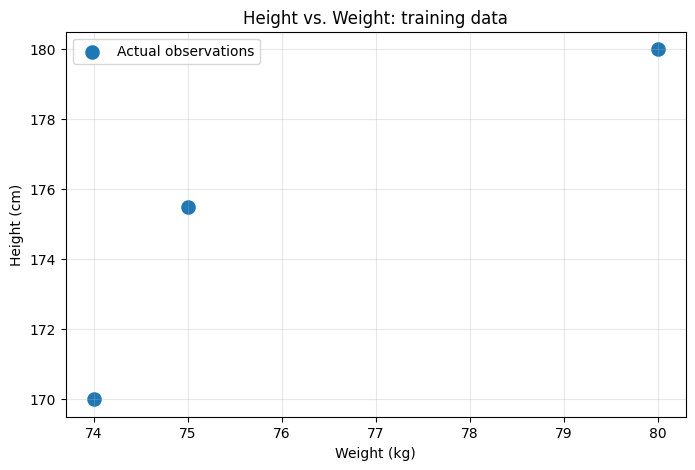

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(X.ravel(), y, s=90, label="Actual observations")
plt.xlabel("Weight (kg)")
plt.ylabel("Height (cm)")
plt.title("Height vs. Weight: training data")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 1.4 Train a Simple Linear Regression model

In [4]:
model = LinearRegression()
model.fit(X, y)

print("Learned slope:", model.coef_[0])
print("Learned intercept:", model.intercept_)
print(f"Learned line: Height = {model.coef_[0]:.3f} × Weight + {model.intercept_:.3f}")


Learned slope: 1.419354838709678
Learned intercept: 66.82258064516125
Learned line: Height = 1.419 × Weight + 66.823


## 1.5 Visualize the best-fit line

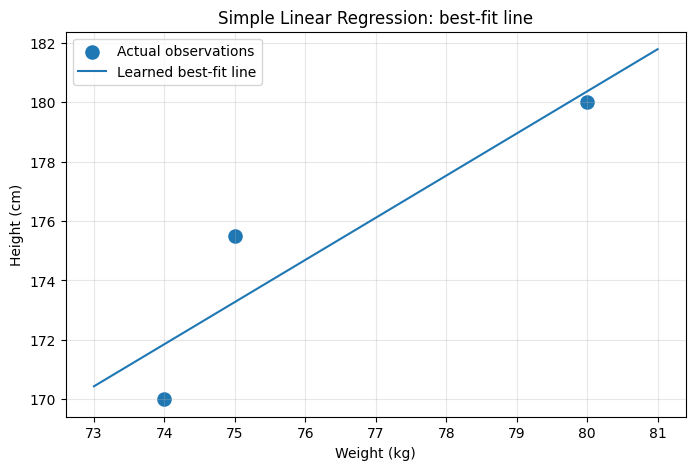

In [5]:
x_line = np.linspace(X.min() - 1, X.max() + 1, 200).reshape(-1, 1)
y_line = model.predict(x_line)

plt.figure(figsize=(8, 5))
plt.scatter(X.ravel(), y, s=90, label="Actual observations")
plt.plot(x_line.ravel(), y_line, label="Learned best-fit line")
plt.xlabel("Weight (kg)")
plt.ylabel("Height (cm)")
plt.title("Simple Linear Regression: best-fit line")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 1.6 Predict for a new input

In [6]:
new_weight = np.array([[77]])
predicted_height = model.predict(new_weight)[0]

print(f"New weight: {new_weight[0, 0]} kg")
print(f"Predicted height: {predicted_height:.2f} cm")


New weight: 77 kg
Predicted height: 176.11 cm


## 1.7 Actual values vs. predicted values

A residual is the signed difference between the actual value and the predicted value:

$$
e_i = y_i - \hat{y}_i
$$

The vertical gap between a data point and the line represents the magnitude of its residual on this graph.

In [7]:
predicted_train = model.predict(X)
residuals = y - predicted_train

results = pd.DataFrame({
    "Weight (kg)": X.ravel(),
    "Actual Height (cm)": y,
    "Predicted Height (cm)": predicted_train,
    "Residual (actual - predicted)": residuals
})
results


,Weight (kg),Actual Height (cm),Predicted Height (cm),Residual (actual - predicted)
0,74,170.0,171.854839,-1.854839
1,80,180.0,180.370968,-0.370968
2,75,175.5,173.274194,2.225806


### Visualize residuals

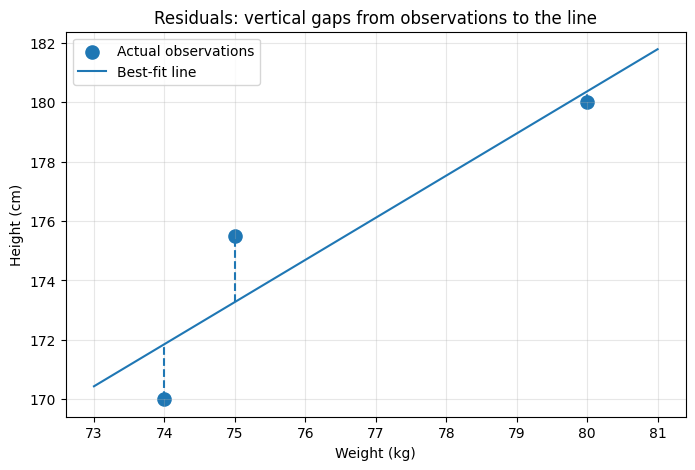

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(X.ravel(), y, s=90, label="Actual observations")
plt.plot(x_line.ravel(), y_line, label="Best-fit line")

for x_value, actual, predicted in zip(X.ravel(), y, predicted_train):
    plt.vlines(x_value, min(actual, predicted), max(actual, predicted), linestyles="dashed")

plt.xlabel("Weight (kg)")
plt.ylabel("Height (cm)")
plt.title("Residuals: vertical gaps from observations to the line")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 1.8 What does “best fit” mean?

Ordinary Linear Regression in scikit-learn fits the line by minimizing the **sum of squared residuals**. The introductory lecture describes this more generally as minimizing overall error; the squared-error objective is the precise least-squares version.

This tiny dataset is for understanding the mechanics, not for making reliable real-world height predictions.

In [9]:
squared_errors = residuals ** 2
print("Residuals:", residuals)
print("Sum of squared errors:", squared_errors.sum())
print("Mean squared error:", np.mean(squared_errors))


Residuals: [-1.85483871 -0.37096774  2.22580645]
Sum of squared errors: 8.53225806451617
Mean squared error: 2.8440860215053902


## 1.9 Self-check

1. Why is this a supervised learning problem?
2. Why is this Simple Linear Regression rather than Multiple Linear Regression?
3. Which variable is the input, and which is the output?
4. What does the best-fit line represent?
5. What is a residual?
6. Why should you be cautious about using this tiny dataset for real predictions?

### Answers

1. The training data includes known output values (heights).
2. There is one input feature: weight.
3. Weight is the input; height is the output.
4. It represents the relationship learned from the training examples.
5. The signed difference between an actual value and its predicted value.
6. Three observations are far too few to establish a reliable real-world relationship; the example is for learning the algorithm's mechanics.


# 2. Understanding Simple Linear Regression Notations

In this section, we explore the model equation, the meaning of its parameters, predicted outputs, residuals, and how different lines compare in terms of prediction error.

The main equation is:

$$
h_\theta(x) = \theta_0 + \theta_1x
$$

Where:
- `x` is the input feature.
- `θ₀` is the intercept.
- `θ₁` is the slope.
- `hθ(x)` is the predicted output.

In [10]:
def predict_output(x, theta_0, theta_1):
    """
    Calculate predictions using:
    h_theta(x) = theta_0 + theta_1 * x
    """
    return theta_0 + theta_1 * x


# Example parameters
theta_0 = 100
theta_1 = 1

weight = 75
predicted_height = predict_output(weight, theta_0, theta_1)

print(f"Weight: {weight} kg")
print(f"Intercept (theta_0): {theta_0}")
print(f"Slope (theta_1): {theta_1}")
print(f"Predicted output: {predicted_height}")

Weight: 75 kg
Intercept (theta_0): 100
Slope (theta_1): 1
Predicted output: 175


## 2.1 Understanding the Intercept (θ₀)

The intercept determines the predicted output when the input is zero:

$$
h_\theta(0) = \theta_0
$$

Changing the intercept shifts the line vertically without changing its slope.

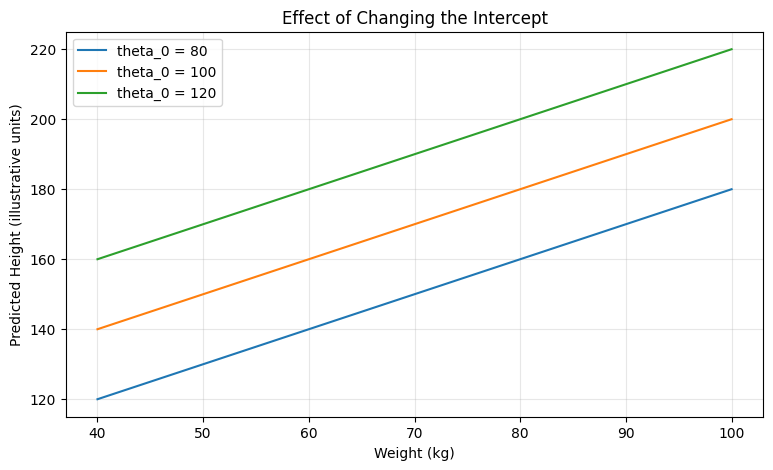

In [11]:
x_values = np.linspace(40, 100, 200)
theta_1 = 1

intercepts = [80, 100, 120]

plt.figure(figsize=(9, 5))

for theta_0 in intercepts:
    y_values = predict_output(x_values, theta_0, theta_1)
    plt.plot(
        x_values,
        y_values,
        label=f"theta_0 = {theta_0}"
    )

plt.xlabel("Weight (kg)")
plt.ylabel("Predicted Height (illustrative units)")
plt.title("Effect of Changing the Intercept")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 2.2 Understanding the Slope (θ₁)

The slope determines how much the predicted output changes when the input increases by one unit.

$$
\Delta \hat{y} = \theta_1 \Delta x
$$

For a one-unit increase in `x`, the change in predicted output equals `θ₁`. A positive slope produces a rising line, while a negative slope produces a falling line.

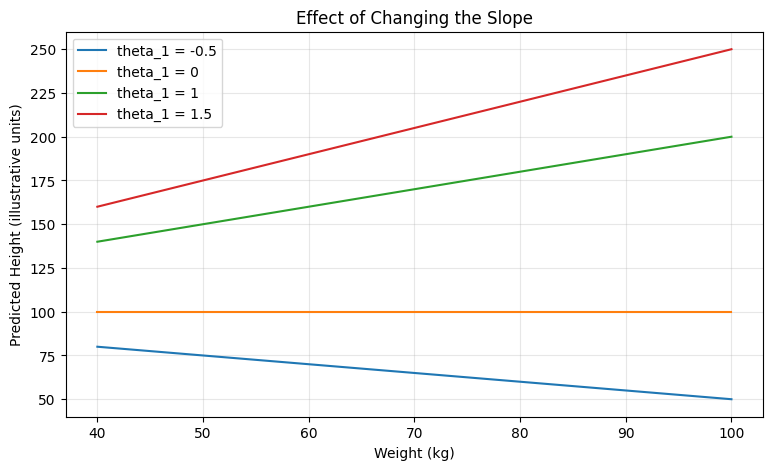

In [12]:
x_values = np.linspace(40, 100, 200)
theta_0 = 100

slopes = [-0.5, 0, 1, 1.5]

plt.figure(figsize=(9, 5))

for theta_1 in slopes:
    y_values = predict_output(x_values, theta_0, theta_1)
    plt.plot(
        x_values,
        y_values,
        label=f"theta_1 = {theta_1}"
    )

plt.xlabel("Weight (kg)")
plt.ylabel("Predicted Height (illustrative units)")
plt.title("Effect of Changing the Slope")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 2.3 Understanding Actual vs. Predicted Values

The actual output is represented by `y`, while the predicted output is represented by `ŷ`.

$$
\hat{y} = h_\theta(x) = \theta_0 + \theta_1x
$$

The residual measures the difference between the actual and predicted values:

$$
e_i = y_i - \hat{y}_i
$$

In [13]:
import pandas as pd

# Illustrative training data
df = pd.DataFrame({
    "Weight": [74, 80, 75],
    "Actual_Height": [170, 180, 175.5]
})

# Example model parameters for demonstration
theta_0 = 100
theta_1 = 1

df["Predicted_Height"] = predict_output(
    df["Weight"],
    theta_0,
    theta_1
)

df["Residual"] = (
    df["Actual_Height"] - df["Predicted_Height"]
)

df["Absolute_Residual"] = df["Residual"].abs()

df

,Weight,Actual_Height,Predicted_Height,Residual,Absolute_Residual
0,74,170.0,174,-4.0,4.0
1,80,180.0,180,0.0,0.0
2,75,175.5,175,0.5,0.5


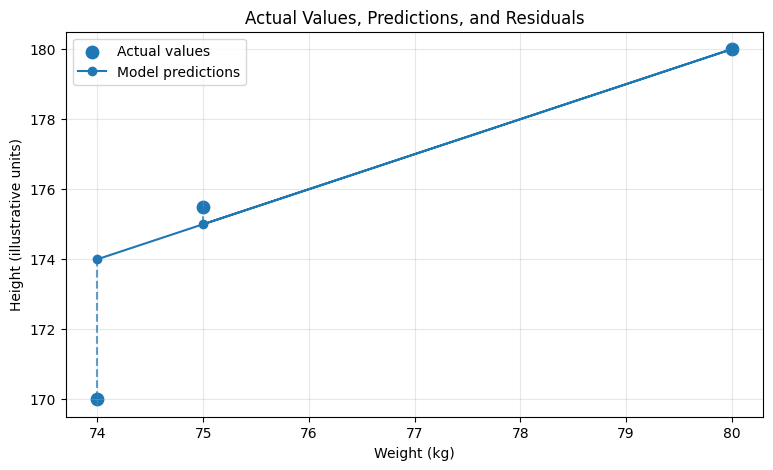

In [14]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Weight"],
    df["Actual_Height"],
    label="Actual values",
    s=80
)

plt.plot(
    df["Weight"],
    df["Predicted_Height"],
    label="Model predictions",
    marker="o"
)

for _, row in df.iterrows():
    plt.vlines(
        x=row["Weight"],
        ymin=min(row["Actual_Height"], row["Predicted_Height"]),
        ymax=max(row["Actual_Height"], row["Predicted_Height"]),
        linestyles="dashed",
        alpha=0.7
    )

plt.xlabel("Weight (kg)")
plt.ylabel("Height (illustrative units)")
plt.title("Actual Values, Predictions, and Residuals")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 2.4 Comparing Lines Using Squared Error

Signed residuals can cancel one another when added. Squaring the residuals avoids this cancellation.

**Sum of Squared Errors (SSE):**

$$
SSE = \sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

**Mean Squared Error (MSE):**

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

For this demonstration, we compare different candidate lines on the same observations. A lower SSE or MSE indicates a better fit to these particular observations under the chosen measure.

In [15]:
# Candidate parameters for demonstration
candidate_lines = [
    {"theta_0": 100, "theta_1": 1},
    {"theta_0": 90, "theta_1": 1.1},
    {"theta_0": 110, "theta_1": 0.8},
]

results = []

for candidate in candidate_lines:
    predictions = predict_output(
        df["Weight"],
        candidate["theta_0"],
        candidate["theta_1"]
    )

    residuals = df["Actual_Height"] - predictions
    sse = (residuals ** 2).sum()
    mse = (residuals ** 2).mean()

    results.append({
        "Theta_0": candidate["theta_0"],
        "Theta_1": candidate["theta_1"],
        "SSE": sse,
        "MSE": mse
    })

comparison = pd.DataFrame(results)
comparison.sort_values("MSE")

,Theta_0,Theta_1,SSE,MSE
1,90,1.1,14.96,4.986667
0,100,1.0,16.25,5.416667
2,110,0.8,66.89,22.296667


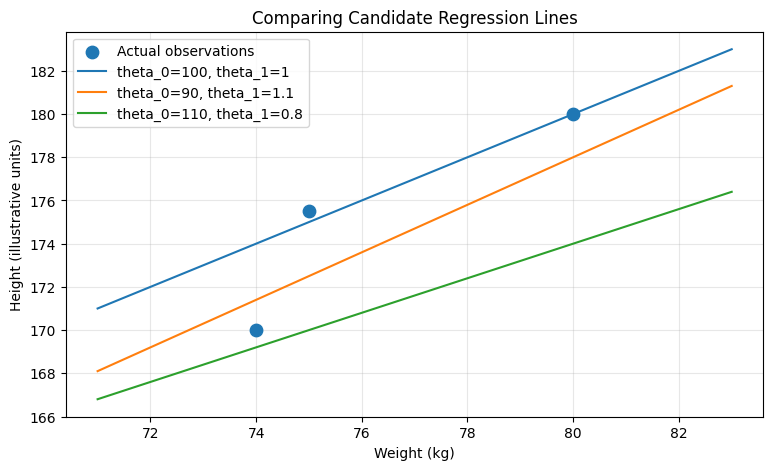

In [16]:
x_values = np.linspace(
    df["Weight"].min() - 3,
    df["Weight"].max() + 3,
    200
)

plt.figure(figsize=(9, 5))

plt.scatter(
    df["Weight"],
    df["Actual_Height"],
    label="Actual observations",
    s=80,
    zorder=3
)

for candidate in candidate_lines:
    y_values = predict_output(
        x_values,
        candidate["theta_0"],
        candidate["theta_1"]
    )

    plt.plot(
        x_values,
        y_values,
        label=(
            f"theta_0={candidate['theta_0']}, "
            f"theta_1={candidate['theta_1']}"
        )
    )

plt.xlabel("Weight (kg)")
plt.ylabel("Height (illustrative units)")
plt.title("Comparing Candidate Regression Lines")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 2.5 Preview: Parameter Optimization

The model parameters determine the line's position and tilt.

1. Choose initial values for `θ₀` and `θ₁`.
2. Calculate predictions.
3. Calculate the chosen error measure.
4. Adjust the parameters.
5. Compare the error and seek a better fit.

This notebook compares a few candidate lines manually. It does not implement a full optimization algorithm; that will be explored in a later lesson.

**Important:** The three observations here are illustrative and are not sufficient to build a reliable real-world height-prediction model.

## 2.6 Self-Check Questions

1. What does `θ₀` represent?
2. What happens to a line when `θ₀` increases while `θ₁` remains fixed?
3. What does `θ₁` represent?
4. If the actual output is 180 and the predicted output is 175, what is the residual?
5. Why can the sum of signed residuals be misleading?
6. What does a lower MSE indicate when comparing candidate models on the same dataset?

### Answers

1. The intercept: the predicted output when x = 0.  
2. The line shifts vertically upward without changing its slope.  
3. The slope: predicted output change for a one-unit increase in x.  
4. Residual = 180 - 175 = 5.  
5. Positive and negative residuals can cancel each other out.  
6. A lower mean squared error on the same dataset indicates a smaller average squared residual.  

# Cost Function & Gradient Descent Intuition


In this section, we will explore how Simple Linear Regression evaluates a candidate line and how optimization aims to find parameters that minimize the cost.

We will use a simplified dataset and temporarily fix the intercept at zero to understand how changing the slope affects the cost.

### Learning objectives

- Understand the squared-error cost function.
- Calculate cost for different candidate slopes.
- Visualize the relationship between slope and cost.
- Identify the global minimum.
- Understand the intuition behind gradient descent.

**Model equation:**

$$
h_\theta(x) = \theta_0 + \theta_1x
$$

In [17]:
# Simplified training dataset
data = pd.DataFrame({
    "x": [1, 2, 3],
    "y": [1, 2, 3]
})

m = len(data)

data

,x,y
0,1,1
1,2,2
2,3,3


## 3.1 Simplifying the Model

To visualize cost against a single parameter, we temporarily fix the intercept:

$$
\theta_0 = 0
$$

The model becomes:

$$
h_\theta(x) = \theta_1x
$$

Every candidate line passes through the origin. Only the slope changes.

This is a simplified example for learning the cost function, not a restriction of Simple Linear Regression in general.

In [18]:
def predict_output(x, theta_0, theta_1):
    """
    Predict outputs using Simple Linear Regression.

    Parameters
    ----------
    x : array-like
        Input feature values.
    theta_0 : float
        Intercept.
    theta_1 : float
        Slope.

    Returns
    -------
    numpy.ndarray
        Predicted output values.
    """
    return theta_0 + theta_1 * np.asarray(x)


# Example prediction with intercept = 0 and slope = 1
theta_0 = 0
theta_1 = 1

predictions = predict_output(data["x"], theta_0, theta_1)

print("Actual values:   ", data["y"].to_numpy())
print("Predicted values:", predictions)

Actual values:    [1 2 3]
Predicted values: [1 2 3]


## 3.2 The Cost Function

The cost function measures the overall squared prediction error for a particular choice of model parameters.

$$
J(\theta_0,\theta_1)
=
\frac{1}{2m}
\sum_{i=1}^{m}
\left(h_\theta(x^{(i)})-y^{(i)}\right)^2
$$

Where:

- $m$ is the number of training examples.
- $h_\theta(x^{(i)})$ is the predicted output.
- $y^{(i)}$ is the actual output.
- $\theta_0$ is the intercept.
- $\theta_1$ is the slope.

The factor $1/2$ simplifies differentiation later.

**Remember:** This cost function is half of the standard MSE.

In [19]:
def compute_cost(x, y, theta_0, theta_1):
    """
    Compute the half-MSE cost for Simple Linear Regression.
    """
    predictions = predict_output(x, theta_0, theta_1)
    errors = predictions - np.asarray(y)

    return np.sum(errors ** 2) / (2 * len(y))


# Test the cost function
cost = compute_cost(
    data["x"],
    data["y"],
    theta_0=0,
    theta_1=1
)

print(f"Cost: {cost:.4f}")

Cost: 0.0000


## 3.3 Comparing Candidate Slopes

Let's evaluate three different candidate slopes:

- $\theta_1 = 1$
- $\theta_1 = 0.5$
- $\theta_1 = 0$

For each candidate, we will calculate the predictions and cost.

A lower cost indicates a better fit according to this cost function.

In [20]:
candidate_slopes = [1, 0.5, 0]

results = []

for slope in candidate_slopes:
    predictions = predict_output(
        data["x"],
        theta_0=0,
        theta_1=slope
    )

    cost = compute_cost(
        data["x"],
        data["y"],
        theta_0=0,
        theta_1=slope
    )

    results.append({
        "Slope (theta_1)": slope,
        "Predictions": predictions.tolist(),
        "Cost": cost
    })

results_df = pd.DataFrame(results)

results_df["Cost"] = results_df["Cost"].round(4)

results_df

,Slope (theta_1),Predictions,Cost
0,1.0,"[1, 2, 3]",0.0000
1,0.5,"[0.5, 1.0, 1.5]",0.5833
2,0.0,"[0, 0, 0]",2.3333


### What do the results tell us?

For the training data $(1,1)$, $(2,2)$, and $(3,3)$:

- **Slope = 1:** Predictions match every actual value, so the cost is zero.
- **Slope = 0.5:** Predictions are too low, resulting in a larger cost.
- **Slope = 0:** Every prediction is zero, producing an even larger cost.

The best candidate among these three is $\theta_1 = 1$.

However, comparing just three candidates does not show the entire cost curve. Let's visualize it.

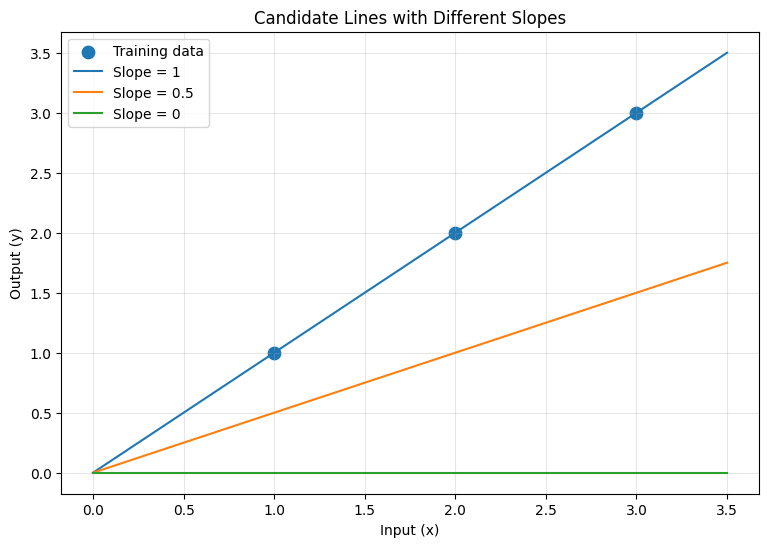

In [21]:
x_line = np.linspace(0, 3.5, 100)

plt.figure(figsize=(9, 6))

plt.scatter(
    data["x"],
    data["y"],
    label="Training data",
    s=80
)

for slope in candidate_slopes:
    y_line = predict_output(x_line, 0, slope)

    plt.plot(
        x_line,
        y_line,
        label=f"Slope = {slope}"
    )

plt.xlabel("Input (x)")
plt.ylabel("Output (y)")
plt.title("Candidate Lines with Different Slopes")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 3.4 Understanding the Cost Curve

With the intercept fixed at zero, the cost depends only on the slope:

$$
J(\theta_1)
=
\frac{1}{2m}
\sum_{i=1}^{m}
(\theta_1x^{(i)}-y^{(i)})^2
$$

For our dataset:

$$
J(\theta_1)
=
\frac{1}{6}
\left[
(\theta_1-1)^2+
(2\theta_1-2)^2+
(3\theta_1-3)^2
\right]
$$

Simplifying gives:

$$
J(\theta_1)=\frac{7}{6}(\theta_1-1)^2
$$

This is a quadratic function with a U-shaped curve.

Its global minimum occurs at:

$$
\theta_1=1,\qquad J(\theta_1)=0
$$

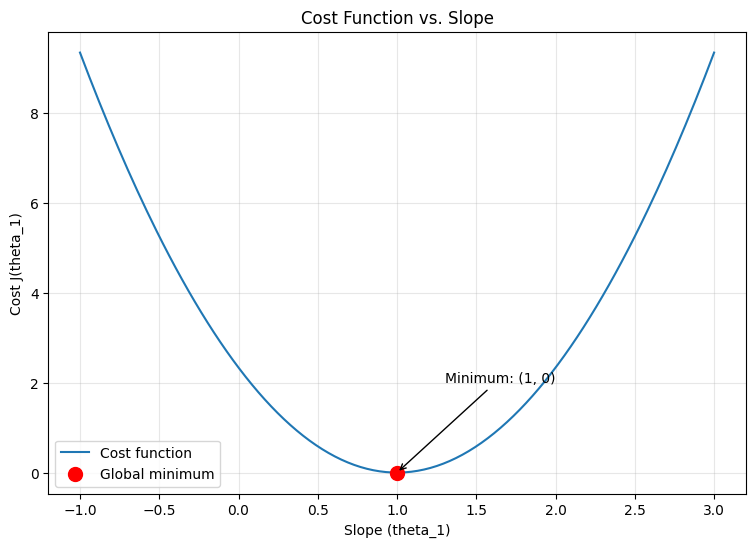

In [22]:
slopes = np.linspace(-1, 3, 200)

costs = [
    compute_cost(
        data["x"],
        data["y"],
        theta_0=0,
        theta_1=slope
    )
    for slope in slopes
]

plt.figure(figsize=(9, 6))

plt.plot(slopes, costs, label="Cost function")

plt.scatter(
    [1],
    [0],
    color="red",
    s=100,
    zorder=3,
    label="Global minimum"
)

plt.annotate(
    "Minimum: (1, 0)",
    xy=(1, 0),
    xytext=(1.3, 2),
    arrowprops={"arrowstyle": "->"}
)

plt.xlabel("Slope (theta_1)")
plt.ylabel("Cost J(theta_1)")
plt.title("Cost Function vs. Slope")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 3.5 Experiment with Different Slopes

Change the slope below and observe how the predictions and cost change.

Think about these questions:

1. What happens to the cost when the slope approaches 1?
2. What happens when the slope moves far away from 1?
3. Can the cost become negative?
4. Which slope gives zero cost for this dataset?

In [ ]:
from ipywidgets import interact, FloatSlider

def explore_slope(theta_1):
    predictions = predict_output(
        data["x"],
        theta_0=0,
        theta_1=theta_1
    )

    cost = compute_cost(
        data["x"],
        data["y"],
        theta_0=0,
        theta_1=theta_1
    )

    x_line = np.linspace(0, 3.5, 100)
    y_line = predict_output(x_line, 0, theta_1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    # Candidate line
    axes[0].scatter(
        data["x"],
        data["y"],
        s=70,
        label="Actual data"
    )
    axes[0].plot(
        x_line,
        y_line,
        label=f"Slope = {theta_1:.2f}"
    )
    axes[0].set_xlabel("Input (x)")
    axes[0].set_ylabel("Output (y)")
    axes[0].set_title("Candidate Line")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Cost curve
    axes[1].plot(slopes, costs, label="Cost curve")
    axes[1].scatter(
        [theta_1],
        [cost],
        color="red",
        s=80,
        label=f"Cost = {cost:.4f}"
    )
    axes[1].set_xlabel("Slope (theta_1)")
    axes[1].set_ylabel("Cost")
    axes[1].set_title("Current Cost")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"Slope: {theta_1:.2f}")
    print(f"Cost:  {cost:.4f}")


interact(
    explore_slope,
    theta_1=FloatSlider(
        value=0,
        min=-1,
        max=3,
        step=0.1,
        description="Slope:",
        continuous_update=False
    )
)

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='Slope:', max=3.0, min=-1.0)…

<function __main__.explore_slope(theta_1)>

## 3.6 Gradient Descent — The Optimization Idea

We have seen that different parameter values produce different costs.

Gradient descent is an iterative optimization algorithm that updates parameters to reduce the cost.

### The general process

1. Start with initial parameter values.
2. Calculate predictions.
3. Calculate the cost.
4. Determine how to change the parameters to reduce the cost.
5. Update the parameters.
6. Repeat until a stopping condition is reached.

In our simplified example, the intercept remains fixed at zero, so only the slope changes.

**Important:** We are not implementing the gradient descent update rule in this lecture. The mathematical update rule and learning rate will be covered in the next lecture.

## 3.7 Self-Check

Try answering these without looking back at the earlier cells.

1. What does the cost function measure?
2. Why do we square the prediction errors?
3. Why does the lecture's cost function divide by $2m$?
4. Why did we fix the intercept at zero?
5. What is the cost when $\theta_1=0.5$?
6. Which slope gives zero cost for this dataset?
7. What is the difference between MSE and half-MSE cost?
8. What is the main purpose of gradient descent?
9. Can the squared-error cost be negative?
10. Does this example mean every real dataset has a minimum at $\theta_1=1$?

### Answers

1. It measures how well a candidate model fits the training data.
2. Squaring prevents cancellation and penalizes larger errors more heavily.
3. The factor 1/2 simplifies differentiation; m averages across examples.
4. To visualize cost as a function of one changing parameter, the slope.
5. 0.5833
6. Slope = 1, giving zero cost.
7. Half-MSE cost is MSE multiplied by 1/2.
8. To iteratively update parameters and reduce the cost.
9. No. Squared-error cost is always nonnegative.
10. No. The result depends on this particular dataset and the fixed-intercept assumption.